# Notebook 2: Exploratory Data Analysis (EDA) & Data Validation

The goal of this notebook is simply to prove that the datasets we built in Notebook 1 are solid and ready for the thesis. We aren't changing or cleaning any data here.

We are just running checks and generating the final charts for the written thesis to show:
* How many movies survived the filtering process.
* The spread of release years and genres.
* That our plot summaries are actually long enough for the NLP model to read.
* Exactly why the Box Office/ROI analysis is limited to a smaller subset of the films.

**Files being checked:**
* `df_thesis_films.csv` (The main dataset)
* `df_semantic_analysis.csv` (The NLP network dataset)
* `df_revenue_analysis.csv` (The commercial success dataset)
* `df_roi_analysis.csv` (The strict budget vs. revenue dataset)

In [ ]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [ ]:
#Imports and display settings

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("Libraries loaded.")

Libraries loaded.


## 1 & 2. Folders and Loading Data
Setting up the file paths to Google Drive and loading the cleaned CSV files we generated in the last notebook.

In [ ]:
# Project paths

# CHANGE THIS if your project folder is different
PROJECT_DIR = Path("/content/drive/MyDrive/thesis_movie_project").resolve()

PROCESSED_CORE_DIR = PROJECT_DIR / "processed" / "core"
OUTPUT_FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"
OUTPUT_TABLES_DIR = PROJECT_DIR / "outputs" / "tables"

OUTPUT_FIGURES_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_TABLES_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_DIR:", PROJECT_DIR)
print("PROCESSED_CORE_DIR:", PROCESSED_CORE_DIR)
print("OUTPUT_FIGURES_DIR:", OUTPUT_FIGURES_DIR)
print("OUTPUT_TABLES_DIR:", OUTPUT_TABLES_DIR)

PROJECT_DIR: /content/drive/MyDrive/thesis_movie_project
PROCESSED_CORE_DIR: /content/drive/MyDrive/thesis_movie_project/processed/core
OUTPUT_FIGURES_DIR: /content/drive/MyDrive/thesis_movie_project/outputs/figures
OUTPUT_TABLES_DIR: /content/drive/MyDrive/thesis_movie_project/outputs/tables


In [ ]:
from pathlib import Path

search_root = Path("/content/drive/MyDrive")

target_files = [
    "df_thesis_films.csv",
    "df_semantic_analysis.csv",
    "df_display_candidates.csv",
    "df_revenue_analysis.csv",
    "df_roi_analysis.csv",
    "filtering_funnel.csv"
]

for target in target_files:
    print(f"\nSearching for: {target}")
    matches = list(search_root.rglob(target))

    if matches:
        for m in matches:
            print("FOUND:", m)
    else:
        print("NOT FOUND")


Searching for: df_thesis_films.csv
FOUND: /content/drive/MyDrive/thesis_movie_project/processed/core/df_thesis_films.csv

Searching for: df_semantic_analysis.csv
FOUND: /content/drive/MyDrive/thesis_movie_project/processed/df_semantic_analysis.csv
FOUND: /content/drive/MyDrive/thesis_movie_project/processed/core/df_semantic_analysis.csv

Searching for: df_display_candidates.csv
FOUND: /content/drive/MyDrive/thesis_movie_project/processed/core/df_display_candidates.csv

Searching for: df_revenue_analysis.csv
FOUND: /content/drive/MyDrive/thesis_movie_project/processed/df_revenue_analysis.csv
FOUND: /content/drive/MyDrive/thesis_movie_project/processed/core/df_revenue_analysis.csv

Searching for: df_roi_analysis.csv
FOUND: /content/drive/MyDrive/thesis_movie_project/processed/df_roi_analysis.csv
FOUND: /content/drive/MyDrive/thesis_movie_project/processed/core/df_roi_analysis.csv

Searching for: filtering_funnel.csv
FOUND: /content/drive/MyDrive/thesis_movie_project/outputs/tables/filte

## 2. Load datasets

In [ ]:
# Load curated datasets

paths = {
    "thesis": PROCESSED_CORE_DIR / "df_thesis_films.csv",
    "semantic": PROCESSED_CORE_DIR / "df_semantic_analysis.csv",
    "display": PROCESSED_CORE_DIR / "df_display_candidates.csv",
    "revenue": PROCESSED_CORE_DIR / "df_revenue_analysis.csv",
    "roi": PROCESSED_CORE_DIR / "df_roi_analysis.csv",
    "funnel": OUTPUT_TABLES_DIR / "filtering_funnel.csv",
}

missing = [name for name, path in paths.items() if not path.exists()]
if missing:
    print("Missing expected files:")
    for name in missing:
        print(f" - {name}: {paths[name]}")
    raise FileNotFoundError("Some input files are missing. Run Notebook 01 first or fix the paths.")

df_thesis = pd.read_csv(paths["thesis"])
df_semantic = pd.read_csv(paths["semantic"])
df_display = pd.read_csv(paths["display"])
df_revenue = pd.read_csv(paths["revenue"])
df_roi = pd.read_csv(paths["roi"])
funnel = pd.read_csv(paths["funnel"])

print("Loaded datasets:")
print("df_thesis:", df_thesis.shape)
print("df_semantic:", df_semantic.shape)
print("df_display:", df_display.shape)
print("df_revenue:", df_revenue.shape)
print("df_roi:", df_roi.shape)
print("funnel:", funnel.shape)

Loaded datasets:
df_thesis: (98037, 24)
df_semantic: (20091, 17)
df_display: (13965, 17)
df_revenue: (13186, 24)
df_roi: (7933, 24)
funnel: (11, 5)


## 3. Basic Integrity Checks
Before we do any thesis analysis, we need to make sure the data isn't broken. This step runs a quick scan to confirm there are zero duplicate TMDB IDs and zero missing titles, years, or overviews in our working files.

In [ ]:
# Basic integrity checks

def basic_report(df, name):
    report = {
        "dataset": name,
        "rows": len(df),
        "columns": df.shape[1],
        "duplicate_tmdb_id": df["tmdb_id"].duplicated().sum() if "tmdb_id" in df.columns else np.nan,
        "missing_title_pct": df["title"].isna().mean() * 100 if "title" in df.columns else np.nan,
        "missing_year_pct": df["release_year"].isna().mean() * 100 if "release_year" in df.columns else np.nan,
        "missing_overview_pct": df["overview"].isna().mean() * 100 if "overview" in df.columns else np.nan,
        "median_vote_count": df["vote_count"].median() if "vote_count" in df.columns else np.nan,
        "median_overview_words": df["overview_word_count"].median() if "overview_word_count" in df.columns else np.nan,
        "min_year": df["release_year"].min() if "release_year" in df.columns else np.nan,
        "max_year": df["release_year"].max() if "release_year" in df.columns else np.nan,
    }
    return report

integrity_report = pd.DataFrame([
    basic_report(df_thesis, "df_thesis_films"),
    basic_report(df_semantic, "df_semantic_analysis"),
    basic_report(df_display, "df_display_candidates"),
    basic_report(df_revenue, "df_revenue_analysis"),
    basic_report(df_roi, "df_roi_analysis"),
])

display(integrity_report)

integrity_report.to_csv(OUTPUT_TABLES_DIR / "eda_integrity_report.csv", index=False)
print("Saved:", OUTPUT_TABLES_DIR / "eda_integrity_report.csv")

,dataset,rows,columns,duplicate_tmdb_id,missing_title_pct,missing_year_pct,missing_overview_pct,median_vote_count,median_overview_words,min_year,max_year
0,df_thesis_films,98037,24,0,0.000,0.000,0.000,7.000,52.000,1990,2024
1,df_semantic_analysis,20091,17,0,0.000,0.000,0.000,94.000,57.000,1990,2024
2,df_display_candidates,13965,17,0,0.000,0.000,0.000,181.000,56.000,1990,2024
3,df_revenue_analysis,13186,24,0,0.000,0.000,0.000,192.000,48.000,1990,2024
4,df_roi_analysis,7933,24,0,0.000,0.000,0.000,510.000,48.000,1990,2024


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/eda_integrity_report.csv


## 4. Filtering funnel

This is one of the most important thesis tables.

It shows that the raw source was broad and noisy, and that the thesis corpus was created using explicit, reproducible rules.

In [ ]:
# Filtering funnel table

display(funnel)

funnel.to_csv(OUTPUT_TABLES_DIR / "eda_filtering_funnel_table.csv", index=False)
print("Saved:", OUTPUT_TABLES_DIR / "eda_filtering_funnel_table.csv")

,step,rows_before,rows_after,rows_removed,pct_kept_from_previous
0,raw_loaded_selected_columns,1192309,1192309,0,100.000
1,released_status_only,1192309,1170497,21812,98.170
2,not_future_release,1170497,1063713,106784,90.880
3,stable_year_window_1990_2024,1063713,727301,336412,68.370
4,usable_title,727301,727281,20,100.000
5,feature_runtime_70_240_minutes,727281,258798,468483,35.580
6,overview_at_least_25_words,258798,200002,58796,77.280
7,has_genre,200002,180239,19763,90.120
8,exclude_tv_movie_genre,180239,170025,10214,94.330
9,exclude_documentary_primary_genre,170025,134792,35233,79.280


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/eda_filtering_funnel_table.csv


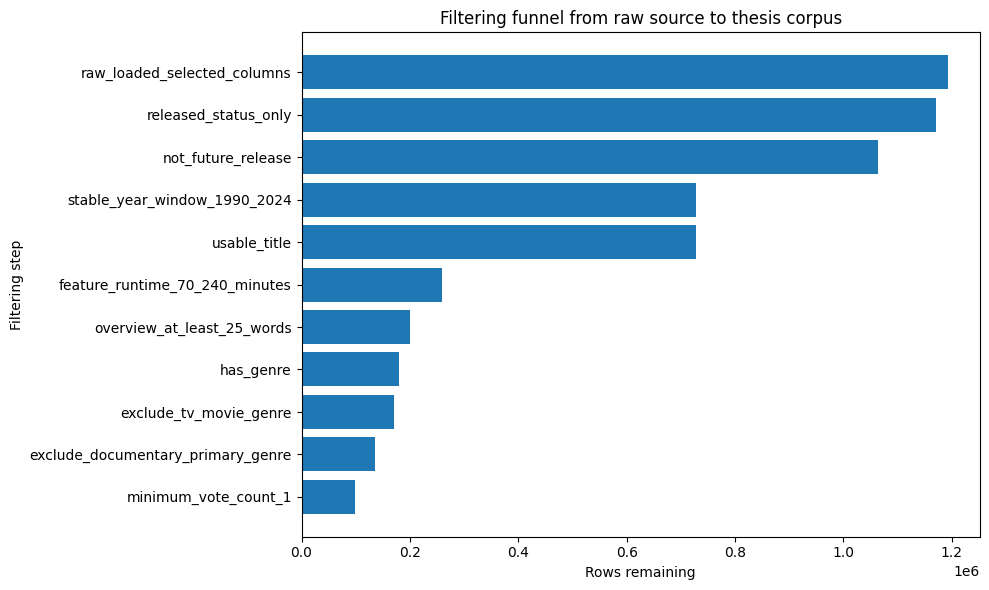

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/figures/filtering_funnel.png


In [ ]:
# Filtering funnel chart

funnel_plot = funnel.copy()

# Try to infer the count column
possible_count_cols = ["rows_after", "n_rows", "rows", "count"]
count_col = next((c for c in possible_count_cols if c in funnel_plot.columns), None)

if count_col is None:
    raise ValueError(f"Could not find a count column in filtering_funnel.csv. Columns: {list(funnel_plot.columns)}")

# Try to infer step-name column
possible_step_cols = ["step", "filter_step", "filter", "stage"]
step_col = next((c for c in possible_step_cols if c in funnel_plot.columns), None)

if step_col is None:
    # fallback: first non-count column
    step_col = [c for c in funnel_plot.columns if c != count_col][0]

plt.figure(figsize=(10, 6))
plt.barh(funnel_plot[step_col].astype(str), funnel_plot[count_col])
plt.xlabel("Rows remaining")
plt.ylabel("Filtering step")
plt.title("Filtering funnel from raw source to thesis corpus")
plt.gca().invert_yaxis()
plt.tight_layout()

fig_path = OUTPUT_FIGURES_DIR / "filtering_funnel.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", fig_path)

## 5. Dataset Comparison Table
A quick summary table to compare our main thesis dataset against the smaller, stricter subsets we are using for the network and financial models.

In [ ]:
# Corpus comparison table

def corpus_summary(df, name):
    out = {
        "dataset": name,
        "rows": len(df),
        "columns": df.shape[1],
        "year_min": df["release_year"].min(),
        "year_max": df["release_year"].max(),
        "median_overview_words": df["overview_word_count"].median() if "overview_word_count" in df.columns else np.nan,
        "median_vote_count": df["vote_count"].median() if "vote_count" in df.columns else np.nan,
        "mean_vote_average": df["vote_average"].mean() if "vote_average" in df.columns else np.nan,
        "revenue_available_pct": df["revenue_clean"].notna().mean() * 100 if "revenue_clean" in df.columns else np.nan,
        "budget_available_pct": df["budget_clean"].notna().mean() * 100 if "budget_clean" in df.columns else np.nan,
        "roi_available_pct": df["roi_clean"].notna().mean() * 100 if "roi_clean" in df.columns else np.nan,
    }
    return out

corpus_comparison = pd.DataFrame([
    corpus_summary(df_thesis, "Thesis corpus"),
    corpus_summary(df_semantic, "Semantic corpus"),
    corpus_summary(df_display, "Display candidates"),
    corpus_summary(df_revenue, "Revenue corpus"),
    corpus_summary(df_roi, "ROI corpus"),
])

display(corpus_comparison)

corpus_comparison.to_csv(OUTPUT_TABLES_DIR / "eda_corpus_comparison.csv", index=False)
print("Saved:", OUTPUT_TABLES_DIR / "eda_corpus_comparison.csv")

,dataset,rows,columns,year_min,year_max,median_overview_words,median_vote_count,mean_vote_average,revenue_available_pct,budget_available_pct,roi_available_pct
0,Thesis corpus,98037,24,1990,2024,52.000,7.000,5.632,13.450,15.284,8.147
1,Semantic corpus,20091,17,1990,2024,57.000,94.000,6.121,39.311,NaN,NaN
2,Display candidates,13965,17,1990,2024,56.000,181.000,6.251,50.233,NaN,NaN
3,Revenue corpus,13186,24,1990,2024,48.000,192.000,6.258,100.000,60.572,60.572
4,ROI corpus,7933,24,1990,2024,48.000,510.000,6.344,100.000,100.000,100.000


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/eda_corpus_comparison.csv


## 6. Release Year Coverage
We need to make sure our dataset isn't heavily biased toward one specific year or full of unreleased future projects. This line chart proves we have a healthy, stable spread of movies from 1990 to 2024.

In [ ]:
# Movies per year

movies_per_year = (
    df_thesis
    .groupby("release_year", dropna=False)
    .size()
    .reset_index(name="n_films")
    .sort_values("release_year")
)

semantic_per_year = (
    df_semantic
    .groupby("release_year", dropna=False)
    .size()
    .reset_index(name="n_semantic_films")
    .sort_values("release_year")
)

year_table = movies_per_year.merge(semantic_per_year, on="release_year", how="left")
year_table["n_semantic_films"] = year_table["n_semantic_films"].fillna(0).astype(int)
year_table["semantic_share_pct"] = year_table["n_semantic_films"] / year_table["n_films"] * 100

display(year_table.tail(15))

year_table.to_csv(OUTPUT_TABLES_DIR / "eda_movies_per_year.csv", index=False)
print("Saved:", OUTPUT_TABLES_DIR / "eda_movies_per_year.csv")

,release_year,n_films,n_semantic_films,semantic_share_pct
20,2010,3127,721,23.057
21,2011,3349,752,22.454
22,2012,3475,723,20.806
23,2013,3799,796,20.953
24,2014,4000,894,22.350
25,2015,4097,878,21.430
26,2016,4251,891,20.960
27,2017,4483,894,19.942
28,2018,4591,932,20.301
29,2019,4641,918,19.780


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/eda_movies_per_year.csv


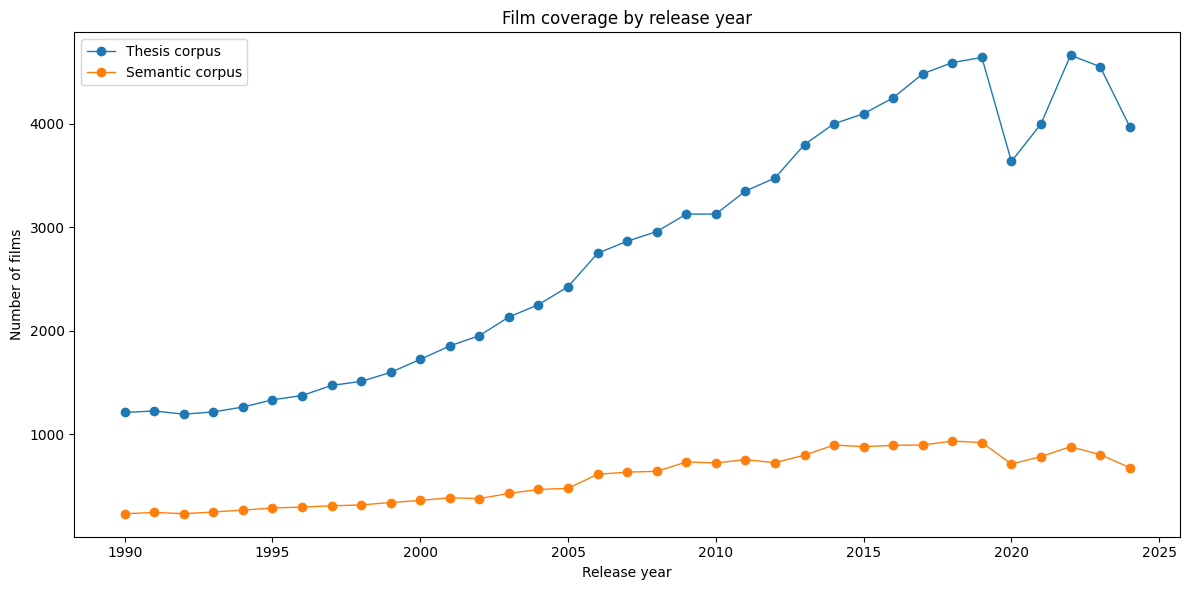

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/figures/movies_per_year.png


In [ ]:
# Year coverage chart

plt.figure(figsize=(12, 6))
plt.plot(year_table["release_year"], year_table["n_films"], marker="o", linewidth=1, label="Thesis corpus")
plt.plot(year_table["release_year"], year_table["n_semantic_films"], marker="o", linewidth=1, label="Semantic corpus")
plt.xlabel("Release year")
plt.ylabel("Number of films")
plt.title("Film coverage by release year")
plt.legend()
plt.tight_layout()

fig_path = OUTPUT_FIGURES_DIR / "movies_per_year.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", fig_path)

## 7. Genre Breakdown
Checking the composition of our dataset to see what types of movies survived the filtering. Drama and Comedy make up the majority of the fictional feature films.

In [ ]:
# Genre counts

genre_counts = (
    df_thesis["primary_genre"]
    .fillna("Unknown")
    .value_counts()
    .rename_axis("primary_genre")
    .reset_index(name="n_films")
)

genre_counts["share_pct"] = genre_counts["n_films"] / len(df_thesis) * 100

display(genre_counts.head(20))

genre_counts.to_csv(OUTPUT_TABLES_DIR / "eda_primary_genre_counts.csv", index=False)
print("Saved:", OUTPUT_TABLES_DIR / "eda_primary_genre_counts.csv")

,primary_genre,n_films,share_pct
0,Drama,31837,32.474
1,Comedy,19805,20.202
2,Action,8972,9.152
3,Horror,8490,8.660
4,Thriller,5290,5.396
5,Romance,4409,4.497
6,Music,4219,4.303
7,Crime,3249,3.314
8,Animation,2476,2.526
9,Family,2040,2.081


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/eda_primary_genre_counts.csv


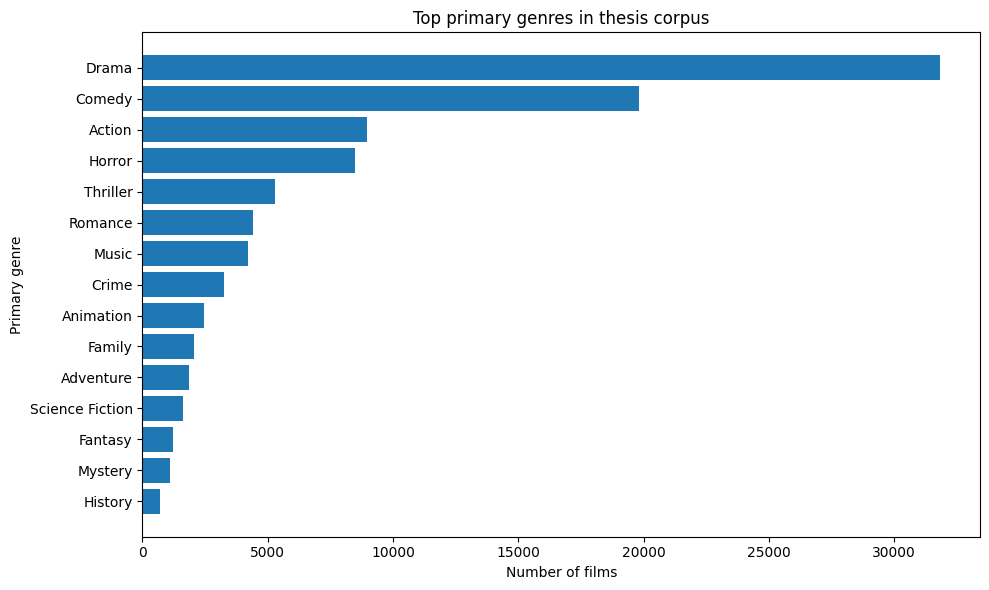

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/figures/top_primary_genres.png


In [ ]:
# Top genres chart

top_genres = genre_counts.head(15).sort_values("n_films", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(top_genres["primary_genre"], top_genres["n_films"])
plt.xlabel("Number of films")
plt.ylabel("Primary genre")
plt.title("Top primary genres in thesis corpus")
plt.tight_layout()

fig_path = OUTPUT_FIGURES_DIR / "top_primary_genres.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", fig_path)

## 8. Text Richness (Plot Lengths)
For the SBERT model to find narrative similarities, it needs enough text to read. This histogram proves that our plot overviews are long enough (averaging around 50-60 words) to generate high-quality semantic embeddings.

In [ ]:
# Overview word count summary

overview_summary = pd.DataFrame({
    "dataset": ["Thesis corpus", "Semantic corpus", "Display candidates"],
    "rows": [len(df_thesis), len(df_semantic), len(df_display)],
    "mean_words": [
        df_thesis["overview_word_count"].mean(),
        df_semantic["overview_word_count"].mean(),
        df_display["overview_word_count"].mean()
    ],
    "median_words": [
        df_thesis["overview_word_count"].median(),
        df_semantic["overview_word_count"].median(),
        df_display["overview_word_count"].median()
    ],
    "p10_words": [
        df_thesis["overview_word_count"].quantile(0.10),
        df_semantic["overview_word_count"].quantile(0.10),
        df_display["overview_word_count"].quantile(0.10)
    ],
    "p90_words": [
        df_thesis["overview_word_count"].quantile(0.90),
        df_semantic["overview_word_count"].quantile(0.90),
        df_display["overview_word_count"].quantile(0.90)
    ],
})

display(overview_summary)

overview_summary.to_csv(OUTPUT_TABLES_DIR / "eda_overview_word_count_summary.csv", index=False)
print("Saved:", OUTPUT_TABLES_DIR / "eda_overview_word_count_summary.csv")

,dataset,rows,mean_words,median_words,p10_words,p90_words
0,Thesis corpus,98037,60.816,52.000,29.000,108.000
1,Semantic corpus,20091,62.577,57.000,38.000,97.000
2,Display candidates,13965,60.976,56.000,38.000,91.000


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/eda_overview_word_count_summary.csv


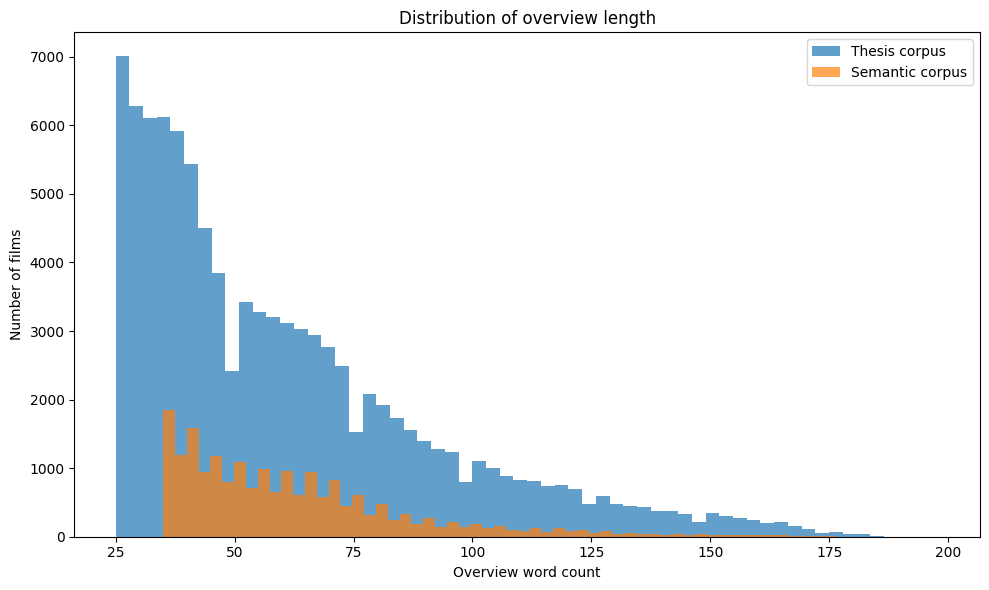

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/figures/overview_word_count_distribution.png


In [ ]:
# Overview word count histogram

plt.figure(figsize=(10, 6))
plt.hist(df_thesis["overview_word_count"].dropna(), bins=60, alpha=0.7, label="Thesis corpus")
plt.hist(df_semantic["overview_word_count"].dropna(), bins=60, alpha=0.7, label="Semantic corpus")
plt.xlabel("Overview word count")
plt.ylabel("Number of films")
plt.title("Distribution of overview length")
plt.legend()
plt.tight_layout()

fig_path = OUTPUT_FIGURES_DIR / "overview_word_count_distribution.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", fig_path)

## 9. Audience Visibility (Vote Counts)
We aren't using vote counts to predict success here; we are just using them as a pulse check. This distribution chart proves that the movies in our network actually have enough audience engagement to be considered "visible" films.

In [ ]:
#Vote count summary

vote_summary = pd.DataFrame({
    "dataset": ["Thesis corpus", "Semantic corpus", "Display candidates"],
    "rows": [len(df_thesis), len(df_semantic), len(df_display)],
    "median_vote_count": [
        df_thesis["vote_count"].median(),
        df_semantic["vote_count"].median(),
        df_display["vote_count"].median()
    ],
    "p75_vote_count": [
        df_thesis["vote_count"].quantile(0.75),
        df_semantic["vote_count"].quantile(0.75),
        df_display["vote_count"].quantile(0.75)
    ],
    "p90_vote_count": [
        df_thesis["vote_count"].quantile(0.90),
        df_semantic["vote_count"].quantile(0.90),
        df_display["vote_count"].quantile(0.90)
    ],
    "max_vote_count": [
        df_thesis["vote_count"].max(),
        df_semantic["vote_count"].max(),
        df_display["vote_count"].max()
    ],
})

display(vote_summary)

vote_summary.to_csv(OUTPUT_TABLES_DIR / "eda_vote_count_summary.csv", index=False)
print("Saved:", OUTPUT_TABLES_DIR / "eda_vote_count_summary.csv")

,dataset,rows,median_vote_count,p75_vote_count,p90_vote_count,max_vote_count
0,Thesis corpus,98037,7.000,29.000,171.000,"39,558.000"
1,Semantic corpus,20091,94.000,320.000,"1,447.000","39,119.000"
2,Display candidates,13965,181.000,603.000,"2,255.000","39,119.000"


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/eda_vote_count_summary.csv


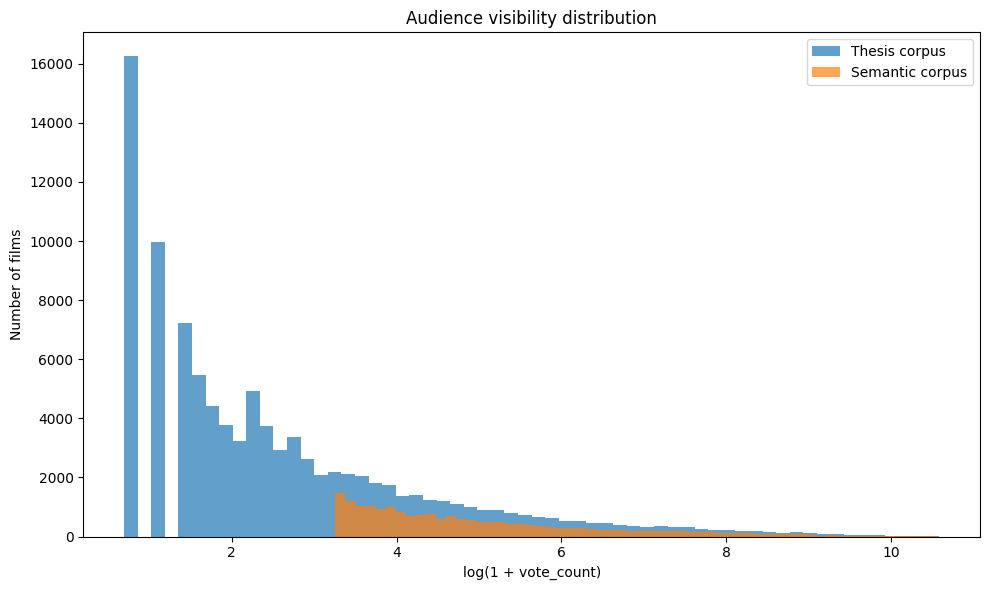

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/figures/log_vote_count_distribution.png


In [ ]:
# Log vote count distribution

plt.figure(figsize=(10, 6))
plt.hist(np.log1p(df_thesis["vote_count"].fillna(0)), bins=60, alpha=0.7, label="Thesis corpus")
plt.hist(np.log1p(df_semantic["vote_count"].fillna(0)), bins=60, alpha=0.7, label="Semantic corpus")
plt.xlabel("log(1 + vote_count)")
plt.ylabel("Number of films")
plt.title("Audience visibility distribution")
plt.legend()
plt.tight_layout()

fig_path = OUTPUT_FIGURES_DIR / "log_vote_count_distribution.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", fig_path)

## 10. The Financial Data Reality
This is a crucial defense for the thesis. It shows that out of our entire movie corpus, only about 13% have published box office revenue, and only 8% have both budget and revenue (ROI). This proves to the review committee exactly why our financial models have to be run on a smaller subset of the overall network.

In [ ]:
# Outcome metadata availability

availability = pd.DataFrame({
    "field": ["revenue_clean", "budget_clean", "roi_clean"],
    "available_rows": [
        df_thesis["revenue_clean"].notna().sum(),
        df_thesis["budget_clean"].notna().sum(),
        df_thesis["roi_clean"].notna().sum(),
    ],
    "available_pct": [
        df_thesis["revenue_clean"].notna().mean() * 100,
        df_thesis["budget_clean"].notna().mean() * 100,
        df_thesis["roi_clean"].notna().mean() * 100,
    ]
})

display(availability)

availability.to_csv(OUTPUT_TABLES_DIR / "eda_outcome_metadata_availability.csv", index=False)
print("Saved:", OUTPUT_TABLES_DIR / "eda_outcome_metadata_availability.csv")

,field,available_rows,available_pct
0,revenue_clean,13186,13.450
1,budget_clean,14984,15.284
2,roi_clean,7987,8.147


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/eda_outcome_metadata_availability.csv


In [ ]:
# Revenue availability by year

revenue_by_year = (
    df_thesis
    .assign(has_revenue=df_thesis["revenue_clean"].notna())
    .groupby("release_year")
    .agg(
        n_films=("tmdb_id", "size"),
        n_with_revenue=("has_revenue", "sum")
    )
    .reset_index()
)

revenue_by_year["revenue_available_pct"] = revenue_by_year["n_with_revenue"] / revenue_by_year["n_films"] * 100

display(revenue_by_year.tail(15))

revenue_by_year.to_csv(OUTPUT_TABLES_DIR / "eda_revenue_availability_by_year.csv", index=False)
print("Saved:", OUTPUT_TABLES_DIR / "eda_revenue_availability_by_year.csv")

,release_year,n_films,n_with_revenue,revenue_available_pct
20,2010,3127,494,15.798
21,2011,3349,492,14.691
22,2012,3475,513,14.763
23,2013,3799,476,12.530
24,2014,4000,553,13.825
25,2015,4097,497,12.131
26,2016,4251,537,12.632
27,2017,4483,594,13.250
28,2018,4591,579,12.612
29,2019,4641,521,11.226


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/eda_revenue_availability_by_year.csv


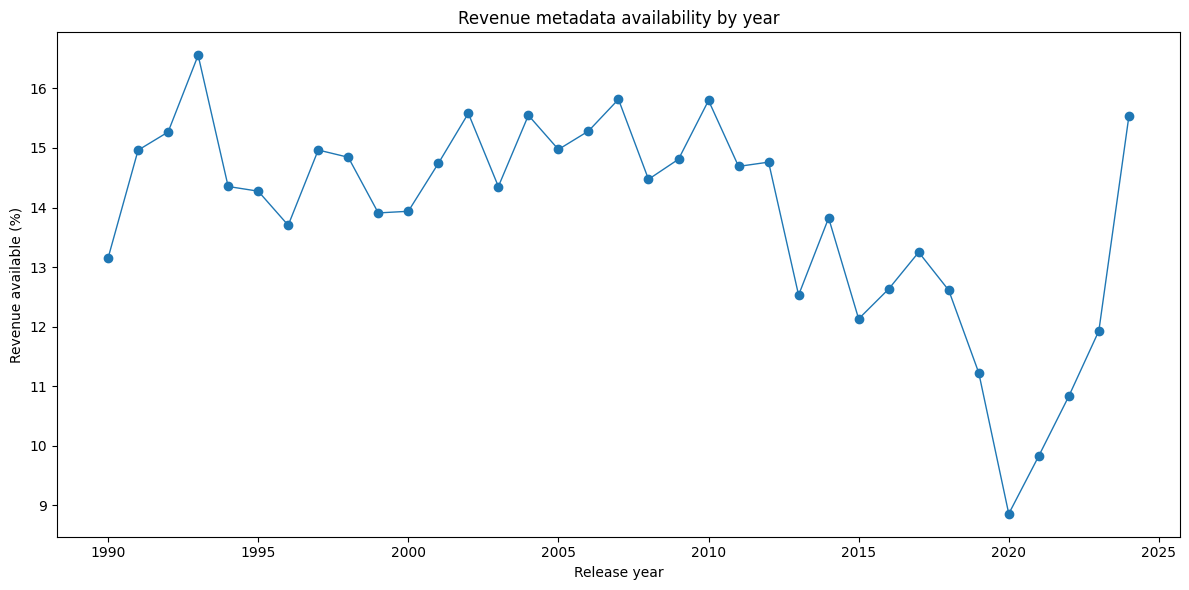

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/figures/revenue_availability_by_year.png


In [ ]:
# Revenue availability chart

plt.figure(figsize=(12, 6))
plt.plot(revenue_by_year["release_year"], revenue_by_year["revenue_available_pct"], marker="o", linewidth=1)
plt.xlabel("Release year")
plt.ylabel("Revenue available (%)")
plt.title("Revenue metadata availability by year")
plt.tight_layout()

fig_path = OUTPUT_FIGURES_DIR / "revenue_availability_by_year.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", fig_path)

## 11. Revenue Percentiles & Enriched Export
Since raw box office numbers naturally suffer from inflation over a 34-year window, we engineered a `revenue_percentile_by_year` metric. This allows a highly successful film from 1990 to be mathematically compared against a blockbuster from 2024. We then export this enriched dataset (`df_revenue_analysis_enriched.csv`) to serve as the foundation for the final financial success models.

In [ ]:
# Create revenue percentiles by year

df_revenue_enriched = df_revenue.copy()

df_revenue_enriched["revenue_percentile_by_year"] = (
    df_revenue_enriched
    .groupby("release_year")["revenue_clean"]
    .rank(pct=True)
)

df_revenue_enriched["high_revenue_by_year"] = (
    df_revenue_enriched["revenue_percentile_by_year"] >= 0.80
).astype(int)

display(
    df_revenue_enriched[
        ["title", "release_year", "revenue_clean", "log_revenue", "revenue_percentile_by_year", "high_revenue_by_year"]
    ]
    .sort_values(["release_year", "revenue_percentile_by_year"], ascending=[False, False])
    .head(20)
)

save_path = PROCESSED_CORE_DIR / "df_revenue_analysis_enriched.csv"
df_revenue_enriched.to_csv(save_path, index=False)
print("Saved:", save_path)

,title,release_year,revenue_clean,log_revenue,revenue_percentile_by_year,high_revenue_by_year
8780,Inside Out 2,2024,"1,698,863,816.000",21.253,1.000,1
11825,Deadpool & Wolverine,2024,"1,338,073,645.000",21.014,0.998,1
6572,Moana 2,2024,"1,059,242,164.000",20.781,0.997,1
12310,Despicable Me 4,2024,"972,021,410.000",20.695,0.995,1
6184,Wicked,2024,"758,827,029.000",20.447,0.994,1
6394,Mufasa: The Lion King,2024,"722,631,756.000",20.398,0.992,1
7138,Dune: Part Two,2024,"714,844,358.000",20.388,0.990,1
6901,Godzilla x Kong: The New Empire,2024,"571,750,016.000",20.164,0.989,1
8708,Kung Fu Panda 4,2024,"548,040,835.000",20.122,0.987,1
8022,Sonic the Hedgehog 3,2024,"492,162,604.000",20.014,0.985,1


Saved: /content/drive/MyDrive/thesis_movie_project/processed/core/df_revenue_analysis_enriched.csv


## 12. Establishing the Baselines of Success (Revenue & Votes)
Here we identify the absolute peaks of our success metrics within the dataset. By sorting for the highest-grossing films (e.g., *Avatar*, *Avengers: Endgame*) and the most highly-voted films (e.g., *Inception*, *The Dark Knight*), we establish the extreme upper bounds of "commercial success" and "audience success" before we begin mapping these outcomes to narrative communities.

In [ ]:
# Top recognizable films by vote_count

top_by_votes = (
    df_display
    .sort_values("vote_count", ascending=False)
    [["title", "release_year", "primary_genre", "vote_average", "vote_count", "popularity"]]
    .head(30)
)

display(top_by_votes)

top_by_votes.to_csv(OUTPUT_TABLES_DIR / "eda_top_films_by_vote_count.csv", index=False)
print("Saved:", OUTPUT_TABLES_DIR / "eda_top_films_by_vote_count.csv")

,title,release_year,primary_genre,vote_average,vote_count,popularity
6803,Inception,2010,Action,8.372,"39,119.000",30.168
4634,The Avengers,2012,Science Fiction,8.015,"37,602.000",46.566
4071,The Dark Knight,2008,Action,8.529,"35,622.000",33.426
7044,Deadpool,2016,Action,7.623,"32,634.000",15.682
1689,Fight Club,1999,Drama,8.400,"31,915.000",26.859
11233,Avengers: Infinity War,2018,Adventure,8.234,"31,790.000",53.518
823,The Shawshank Redemption,1994,Drama,8.700,"30,251.000",46.191
803,Pulp Fiction,1994,Thriller,8.484,"30,083.000",32.907
725,Forrest Gump,1994,Comedy,8.464,"29,638.000",30.192
2291,Harry Potter and the Philosopher's Stone,2001,Adventure,7.898,"29,457.000",24.006


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/eda_top_films_by_vote_count.csv


In [ ]:
# Top revenue films within revenue corpus

top_by_revenue = (
    df_revenue
    .sort_values("revenue_clean", ascending=False)
    [["title", "release_year", "primary_genre", "revenue_clean", "budget_clean", "roi_clean", "vote_count"]]
    .head(30)
)

display(top_by_revenue)

top_by_revenue.to_csv(OUTPUT_TABLES_DIR / "eda_top_films_by_revenue.csv", index=False)
print("Saved:", OUTPUT_TABLES_DIR / "eda_top_films_by_revenue.csv")

,title,release_year,primary_genre,revenue_clean,budget_clean,roi_clean,vote_count
4405,Avatar,2009,Science Fiction,"2,923,706,026.000","237,000,000.000",12.336,"33,857.000"
10736,Avengers: Endgame,2019,Adventure,"2,799,439,100.000","356,000,000.000",7.864,"27,599.000"
7484,Avatar: The Way of Water,2022,Action,"2,353,096,253.000","350,000,000.000",6.723,"14,019.000"
1481,Titanic,1997,Drama,"2,264,162,353.000","200,000,000.000",11.321,"27,067.000"
9267,Star Wars: The Force Awakens,2015,Adventure,"2,068,223,624.000","245,000,000.000",8.442,"20,470.000"
10735,Avengers: Infinity War,2018,Adventure,"2,052,415,039.000","300,000,000.000",6.841,"31,790.000"
5414,Spider-Man: No Way Home,2021,Action,"1,921,847,111.000","200,000,000.000",9.609,"21,881.000"
8780,Inside Out 2,2024,Animation,"1,698,863,816.000","200,000,000.000",8.494,"6,626.000"
3254,Jurassic World,2015,Adventure,"1,671,537,444.000","150,000,000.000",11.144,"21,501.000"
11740,The Lion King,2019,Adventure,"1,662,020,819.000","260,000,000.000",6.392,"10,720.000"


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/eda_top_films_by_revenue.csv


## 13. Testing the Semantic Thresholds
Before committing to the final parameters for our NLP network, we ran a diagnostic test to see how different word count limits (35, 50, 75 words) and vote thresholds (10, 25, 50, 100 votes) impacted our dataset size. We chose a minimum of 35 words and 10 votes, yielding a highly stable semantic corpus of 32,501 films. This guarantees the SBERT model has enough text to read without needlessly destroying the sample size.

In [ ]:
# Alternative semantic corpus thresholds

threshold_rows = []

for min_votes in [10, 25, 50, 100]:
    for min_words in [35, 50, 75]:
        temp = df_thesis[
            (df_thesis["vote_count"].fillna(0) >= min_votes) &
            (df_thesis["overview_word_count"].fillna(0) >= min_words)
        ]
        threshold_rows.append({
            "min_vote_count": min_votes,
            "min_overview_words": min_words,
            "rows": len(temp),
            "median_vote_count": temp["vote_count"].median() if len(temp) else np.nan,
            "median_overview_words": temp["overview_word_count"].median() if len(temp) else np.nan,
            "revenue_available_pct": temp["revenue_clean"].notna().mean() * 100 if len(temp) else np.nan,
        })

threshold_diagnostics = pd.DataFrame(threshold_rows)

display(threshold_diagnostics)

threshold_diagnostics.to_csv(OUTPUT_TABLES_DIR / "eda_semantic_threshold_diagnostics.csv", index=False)
print("Saved:", OUTPUT_TABLES_DIR / "eda_semantic_threshold_diagnostics.csv")

,min_vote_count,min_overview_words,rows,median_vote_count,median_overview_words,revenue_available_pct
0,10,35,32501,37.000,58.000,27.018
1,10,50,20915,35.000,71.000,26.350
2,10,75,9014,27.000,95.000,20.690
3,25,35,20091,94.000,57.000,39.311
4,25,50,12542,89.000,69.000,39.204
5,25,75,4735,70.000,92.000,33.474
6,50,35,13965,181.000,56.000,50.233
7,50,50,8570,174.000,67.000,50.618
8,50,75,2947,135.000,90.000,44.791
9,100,35,9781,338.000,55.000,61.885


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/eda_semantic_threshold_diagnostics.csv


## 14. Final EDA summary for thesis notes

Use this summary as a basis for the methodology/data chapter.

In [ ]:
# Auto-generated summary text

summary_lines = []

summary_lines.append(f"The curated thesis corpus contains {len(df_thesis):,} released, feature-length, non-documentary, non-TV films.")
summary_lines.append(f"The semantic analysis corpus contains {len(df_semantic):,} films with sufficient plot text and minimum audience signal.")
summary_lines.append(f"The display subset contains {len(df_display):,} films with stronger audience visibility for thesis examples and tables.")
summary_lines.append(f"Release years range from {int(df_thesis['release_year'].min())} to {int(df_thesis['release_year'].max())}.")
summary_lines.append(f"The median overview length in the semantic corpus is {df_semantic['overview_word_count'].median():.0f} words.")
summary_lines.append(f"The median vote count in the semantic corpus is {df_semantic['vote_count'].median():.0f}.")
summary_lines.append(f"Revenue is available for {df_thesis['revenue_clean'].notna().mean()*100:.1f}% of the thesis corpus, so commercial-success analysis is treated as a subset analysis.")
summary_lines.append(f"ROI is available for {df_thesis['roi_clean'].notna().mean()*100:.1f}% of the thesis corpus and should be interpreted cautiously.")

summary_text = "\n".join(summary_lines)

print(summary_text)

with open(OUTPUT_TABLES_DIR / "eda_summary_notes.txt", "w", encoding="utf-8") as f:
    f.write(summary_text)

print("Saved:", OUTPUT_TABLES_DIR / "eda_summary_notes.txt")

The curated thesis corpus contains 98,037 released, feature-length, non-documentary, non-TV films.
The semantic analysis corpus contains 20,091 films with sufficient plot text and minimum audience signal.
The display subset contains 13,965 films with stronger audience visibility for thesis examples and tables.
Release years range from 1990 to 2024.
The median overview length in the semantic corpus is 57 words.
The median vote count in the semantic corpus is 94.
Revenue is available for 13.5% of the thesis corpus, so commercial-success analysis is treated as a subset analysis.
ROI is available for 8.1% of the thesis corpus and should be interpreted cautiously.
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/eda_summary_notes.txt


## 15. Next step

After this notebook, move to:

```text
03_sbert_network_main.ipynb
```

That notebook should:

1. load `df_semantic_analysis.csv`
2. compute SBERT/MiniLM embeddings using `text_semantic_plot`
3. build a mutual KNN graph
4. keep the largest connected component
5. run Louvain community detection
6. compute centrality metrics
7. export network tables for interpretation